# d4 · Pruning: zero out weights, or remove channels?

Two ways to remove parameters from a trained student, each followed by fine-tuning:

* **Unstructured (magnitude) pruning.** Set the smallest |w| to zero, globally across all layers, so layers that
  matter less lose more. The model keeps its shape; the zeros only save bytes if stored sparsely (d1: 1-bit mask
  plus nonzero values) and need sparse kernels to run faster. Sparsity is ramped up gradually over 10 epochs
  (Zhu & Gupta 2017) while training continues, then held while fine-tuning. Levels: 50, 75, 90, 95 %.
* **Structured pruning (channel slimming).** Remove whole channels, keeping those with the largest BatchNorm scale
  |γ| (Liu et al. 2017), then fine-tune. The result is simply a narrower dense model, so it runs faster
  everywhere. The real question is whether **slimming a wider trained model beats training the narrow model
  directly** (d2/d3), so it is compared exactly against that.

**Starting points** (from d3): the two reference students (smallest at or above 0.95 and at or above 0.85) and
the next larger frontier model above the 0.95 one (the teacher's own layout, 1,080 kB, distilled), each
trained the way d3 found best for it.

**Fine-tuning recipe**: as the student was trained (with the teacher if it was distilled), but at **lr 0.003**
(a tenth of the training lr: the start is already a good model, and lr 0.03 would throw much of it away),
30 epochs, early stopping with patience 10 counted only once the target sparsity is reached.

**Control.** Every starting point is also fine-tuned with exactly this recipe *without* pruning ("0 %, fine-tuned
only"). Pruning is judged against that, not against the original model, so 30 extra epochs at a lower learning
rate are not credited to pruning.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from dataclasses import replace
from lib import compress as C, dreport as R
from lib.train import RESULTS
from lib.data import ARTIFACTS
D3 = json.loads((ARTIFACTS / "d3_students.json").read_text())
KD = D3["kd"]
S = pd.DataFrame(D3["students"]).set_index("name").sort_values("bytes")
S = S[S.run.notna()]          # a start needs stored weights for all 3 seeds
W = lambda w0: (w0, 2 * w0, 4 * w0, 8 * w0)
def cfg_of(name, exp, newname, **kw):
    a = S.loc[name]
    c = R.student(exp, newname, block=a.block, kernel=int(a.kernel), stem_kernel=int(a.kernel), widths=W(int(a.w0)))
    return replace(c, **kw)
def runs_of(name):
    exp, n = S.loc[name, "run"].split("/")
    return [json.loads((RESULTS / exp / f"{n}_s{s}.json").read_text()) for s in R.SEEDS3]
hi = S[S.bal_acc >= R.FLOORS["high-performance"]]
lo = S[S.bal_acc >= R.FLOORS["tiny"]]
starts = []
if len(hi): starts.append(hi.index[0])
bigger = S[S.bytes > (S.loc[starts[0], "bytes"] if starts else 0)]
if len(bigger): starts.append(bigger.index[0])
if len(lo) and lo.index[0] not in starts: starts.append(lo.index[0])
print("starting points:"); display(S.loc[starts, ["block", "kernel", "w0", "method", "bytes", "bal_acc"]])
FT = dict(lr=0.003, epochs=30, patience=10)
def ft_extra(name):   # fine-tune the way the student was trained
    return {"kd": KD} if S.loc[name, "method"] == "distilled" else {}

starting points:


,block,kernel,w0,method,bytes,bal_acc
name,,,,,,
dwsep_k5_w32,dwsep,5,32,labels only,212112,0.9643
single_k5_w16,single,5,16,distilled,1105488,0.9710
dwsep_k5_w4,dwsep,5,4,distilled,7264,0.8685


## 1. Unstructured magnitude pruning

In [2]:
LEVELS = [0.5, 0.75, 0.9, 0.95]
unst = {}
for st in starts:
    unst[st] = {"0 %": runs_of(st)}
    # control: the same fine-tuning without pruning, so that any gain is not mistaken for an effect of pruning
    base0 = cfg_of(st, "d4", f"{st}_{S.loc[st, 'method'][:4]}_prune0", **FT)
    unst[st]["0 %, fine-tuned only"] = [R.run(R.with_src(base0, S.loc[st, "run"], "init", s, **ft_extra(st),
                                                         prune={"sparsity": 0.0, "ramp": 10})) for s in R.SEEDS3]
    for sp in LEVELS:
        base = cfg_of(st, "d4", f"{st}_{S.loc[st, 'method'][:4]}_prune{int(sp * 100)}", **FT)
        unst[st][f"{int(sp * 100)} %"] = [R.run(R.with_src(base, S.loc[st, "run"], "init", s, **ft_extra(st),
                                                          prune={"sparsity": sp, "ramp": 10})) for s in R.SEEDS3]
tabs_u = {st: R.table(v) for st, v in unst.items()}
for st, tt in tabs_u.items():
    print(st); display(tt[["sparsity", "kB", "x smaller than teacher", "bal_acc", "sd", "tumor_auc"]])

dwsep_k5_w32


,sparsity,kB,x smaller than teacher,bal_acc,sd,tumor_auc
0 %,0.00,207.1406,5.2118,0.9643,0.0009,0.9979
"0 %, fine-tuned only",0.00,207.1406,5.2118,0.9708,0.0079,0.9976
50 %,0.50,111.4570,9.6860,0.9696,0.0079,0.9977
75 %,0.75,60.4258,17.8662,0.9598,0.0075,0.9967
90 %,0.90,29.8086,36.2170,0.8624,0.0144,0.9811
95 %,0.95,19.6016,55.0761,0.4685,0.1895,0.7776


single_k5_w16


,sparsity,kB,x smaller than teacher,bal_acc,sd,tumor_auc
0 %,0.00,1079.5781,1.0000,0.9710,0.0032,0.9978
"0 %, fine-tuned only",0.00,1079.5781,1.0000,0.9738,0.0012,0.9983
50 %,0.50,574.0020,1.8808,0.9735,0.0009,0.9980
75 %,0.75,304.3613,3.5470,0.9692,0.0012,0.9973
90 %,0.90,142.5801,7.5717,0.9257,0.0166,0.9919
95 %,0.95,88.6504,12.1779,0.7743,0.0755,0.9830


dwsep_k5_w4


,sparsity,kB,x smaller than teacher,bal_acc,sd,tumor_auc
0 %,0.0000,7.0938,152.1872,0.8685,0.0086,0.9786
"0 %, fine-tuned only",0.0000,7.0938,152.1872,0.8828,0.0060,0.9789
50 %,0.5000,3.9521,273.1623,0.8580,0.0086,0.9766
75 %,0.7500,2.2764,474.2548,0.5651,0.2739,0.8850
90 %,0.8998,1.2725,848.4175,0.3477,0.1692,0.5928
95 %,0.9499,0.9365,1152.7508,0.2500,0.0000,0.5000


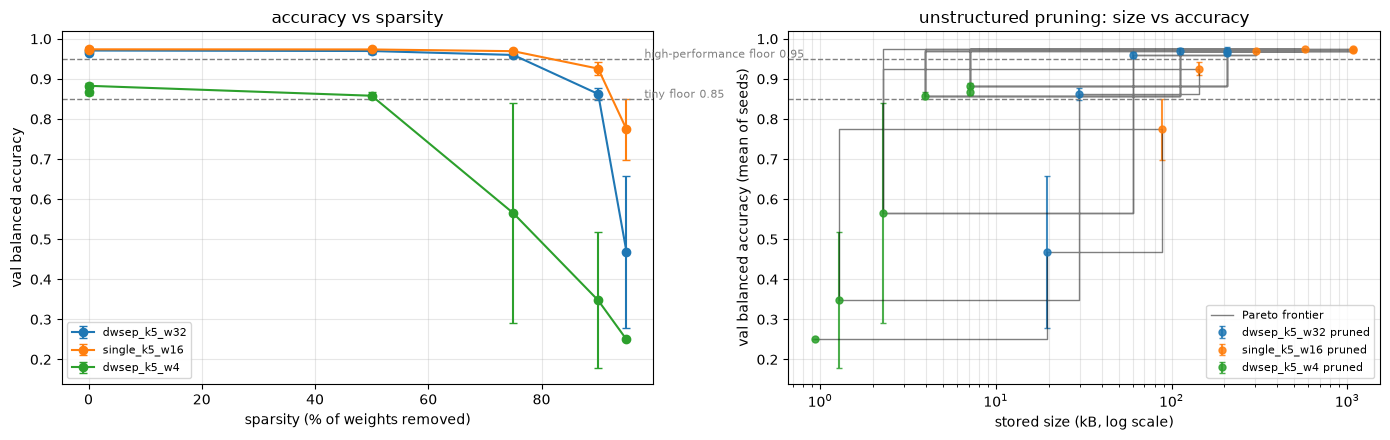

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, (st, tt) in enumerate(tabs_u.items()):
    ax[0].errorbar(tt.sparsity.astype(float) * 100, tt.bal_acc.astype(float), yerr=tt.sd.astype(float).fillna(0), marker="o",
                   capsize=3, label=st, color=f"C{i}")
ax[0].set(xlabel="sparsity (% of weights removed)", ylabel="val balanced accuracy", title="accuracy vs sparsity")
ax[0].grid(alpha=0.3); ax[0].legend(fontsize=8)
for fl in R.FLOORS.values(): ax[0].axhline(fl, ls="--", color="grey", lw=1)
R.tradeoff_plot({f"{st} pruned": tt for st, tt in tabs_u.items()}, "unstructured pruning: size vs accuracy", ax=ax[1])
plt.tight_layout(); plt.show()

**Result** (mean val balanced accuracy, 3 seeds):

| start | original | fine-tuned only (control) | 50 % | 75 % | 90 % | 95 % |
|---|---|---|---|---|---|---|
| dw-sep 5x5 w32, 207 kB | 0.964 | **0.971** | 0.970 (111 kB) | 0.960 (60 kB) | 0.862 (30 kB) | 0.469 (20 kB) |
| teacher layout (distilled), 1,080 kB | 0.971 | **0.974** | 0.974 (574 kB) | 0.969 (304 kB) | 0.926 (143 kB) | 0.774 (89 kB) |
| dw-sep 5x5 w4 (distilled), 7.1 kB | 0.869 | **0.883** | 0.858 (4.0 kB) | 0.565 (2.3 kB) | 0.348 | 0.250 (chance) |

* **The control matters.** Without it, 50 % pruning would look like it *improves* the 207 kB model (0.964 to 0.970).
  The control shows that gain comes from the 30 extra epochs at lr 0.003, not from pruning: fine-tuning alone gives
  0.971. Measured against the control, 50 % pruning costs 0.0 to 0.1 pp on the two larger models and 2.5 pp on
  the 7 kB one.
* **Larger models tolerate more pruning.** Against their fine-tuned controls, at 75 % the 207 kB model loses 1.1 pp
  and the 1,080 kB model 0.5 pp, and both collapse only at 90-95 %; the 7 kB model already collapses at 75 % (sd 0.27: some seeds keep working, others do not).
  A model with few weights has little redundancy to remove.
* **Size gain is smaller than the sparsity.** Sparse storage needs a 1-bit mask over every position, so 50 %
  sparsity saves 46 %, and 90 % saves 86 %.
* **Side finding.** A second phase at a tenth of the learning rate adds 0.3 to 1.4 pp to every model. The c-series
  recipe (constant lr, early stopping) ends slightly too early; a step-down at the end would likely help the
  teacher too. (c6 tested step decay at fixed epochs, not "train, then fine-tune at lr/10".)

## 2. Structured pruning (channel slimming) vs training the narrow model directly

In [4]:
REG = {}   # label -> (runs, stored record "exp/name" without seed): every model of this notebook, for the frontier
for st in S.index:
    REG[f"{st} ({S.loc[st, 'method']})"] = (runs_of(st), S.loc[st, "run"])
for st, v in unst.items():
    REG[f"{st} fine-tuned, not pruned"] = (v["0 %, fine-tuned only"], f"d4/{st}_{S.loc[st, 'method'][:4]}_prune0")
    for sp in LEVELS:
        REG[f"{st} pruned {int(sp * 100)} %"] = (v[f"{int(sp * 100)} %"], f"d4/{st}_{S.loc[st, 'method'][:4]}_prune{int(sp * 100)}")
struct = {}
for st in starts[:2]:
    w0 = int(S.loc[st, "w0"])
    fam = f"{S.loc[st, 'block']}_k{int(S.loc[st, 'kernel'])}"
    for f in [2, 4]:
        nw = w0 // f
        if nw < 1: continue
        sname = f"{st}_{S.loc[st, 'method'][:4]}_slim_w{nw}"
        base = cfg_of(st, "d4", sname, widths=W(nw), **FT)
        sl = [R.run(R.with_src(base, S.loc[st, "run"], "slim", s, **ft_extra(st))) for s in R.SEEDS3]
        # the same narrow architecture trained directly: labels only (d2) and distilled (d3 setting)
        dname = f"{fam}_w{nw}_kdT{KD['T']}a{KD['alpha']}"
        opts = {f"slimmed from w{w0}, fine-tuned": (sl, f"d4/{sname}"),
                "trained directly, labels only": (R.run_seeds(cfg_of(st, "d2", f"{fam}_w{nw}", widths=W(nw))), f"d2/{fam}_w{nw}"),
                "trained directly, distilled": (R.run_seeds(cfg_of(st, "d3", dname, widths=W(nw), extra={"kd": KD})), f"d3/{dname}")}
        struct[(st, nw)] = opts
        for k, v in opts.items():
            REG[f"{fam}_w{nw}: {k}"] = v
rows = []
for (st, nw), opts in struct.items():
    tt = R.table({k: v[0] for k, v in opts.items()})
    for k, r in tt.iterrows():
        rows.append({"from": st, "to width": nw, "how": k, "kB": r.kB, "bal_acc": r.bal_acc, "sd": r.sd})
TS = pd.DataFrame(rows); display(TS.round(4))

,from,to width,how,kB,bal_acc,sd
0,dwsep_k5_w32,16,"slimmed from w32, fine-tuned",60.5781,0.9359,0.0037
1,dwsep_k5_w32,16,"trained directly, labels only",60.5781,0.9415,0.0018
2,dwsep_k5_w32,16,"trained directly, distilled",60.5781,0.9441,0.0088
3,dwsep_k5_w32,8,"slimmed from w32, fine-tuned",19.5469,0.8533,0.0018
4,dwsep_k5_w32,8,"trained directly, labels only",19.5469,0.9158,0.0062
5,dwsep_k5_w32,8,"trained directly, distilled",19.5469,0.8983,0.0130
6,single_k5_w16,8,"slimmed from w16, fine-tuned",271.0469,0.9574,0.0049
7,single_k5_w16,8,"trained directly, labels only",271.0469,0.9527,0.0142
8,single_k5_w16,8,"trained directly, distilled",271.0469,0.9543,0.0172
9,single_k5_w16,4,"slimmed from w16, fine-tuned",68.3438,0.8847,0.0036


**Result.** Slimming a wider trained model and fine-tuning it is **worse than training the narrow model directly**
in 3 of 4 cases, by a lot when the cut is large:

| target | slimmed and fine-tuned | trained directly (labels) | trained directly (distilled) |
|---|---|---|---|
| dw-sep 5x5 w16 (from w32), 61 kB | 0.936 | 0.942 | 0.944 |
| dw-sep 5x5 w8 (from w32), 20 kB | 0.853 | **0.916** | 0.898 |
| plain 5x5 w8 (from w16), 271 kB | **0.957** | 0.953 | 0.954 |
| plain 5x5 w4 (from w16), 68 kB | 0.885 | 0.929 | **0.930** |

Removing 75 % of the channels (w32 to w8, w16 to w4) loses 4 to 6 pp against training that width from scratch;
removing half is roughly a tie. The fine-tuning budget (30 epochs at lr 0.003) is probably too small to recover
from a large cut, but the comparison with direct training is what matters for this task: **for a narrower model,
train it directly.** Structured pruning is dropped.

## 3. Frontier after pruning

,kB,x smaller than teacher,params,sparsity,bal_acc,sd
dwsep_k5_w4 pruned 95 %,0.9365,1152.7508,1912,0.9499,0.2500,0.0000
dwsep_k5_w4 pruned 90 %,1.2725,848.4175,1912,0.8998,0.3477,0.1692
dwsep_k5_w4 pruned 75 %,2.2764,474.2548,1912,0.7500,0.5651,0.2739
dwsep_k5_w2 (labels only),2.8828,374.4878,786,0.0000,0.7946,0.0248
dwsep_k5_w4 pruned 50 %,3.9521,273.1623,1912,0.5000,0.8580,0.0086
"dwsep_k5_w4 fine-tuned, not pruned",7.0938,152.1872,1912,0.0000,0.8828,0.0060
dwsep_k3_w8 (labels only),15.0469,71.7477,4044,0.0000,0.8906,0.0148
dwsep_k5_w8 (labels only),19.5469,55.2302,5196,0.0000,0.9158,0.0062
dwsep_k3_w16 (labels only),51.5781,20.9309,13588,0.0000,0.9484,0.0045
dwsep_k5_w32 pruned 75 %,60.4258,17.8662,53796,0.7500,0.9598,0.0075


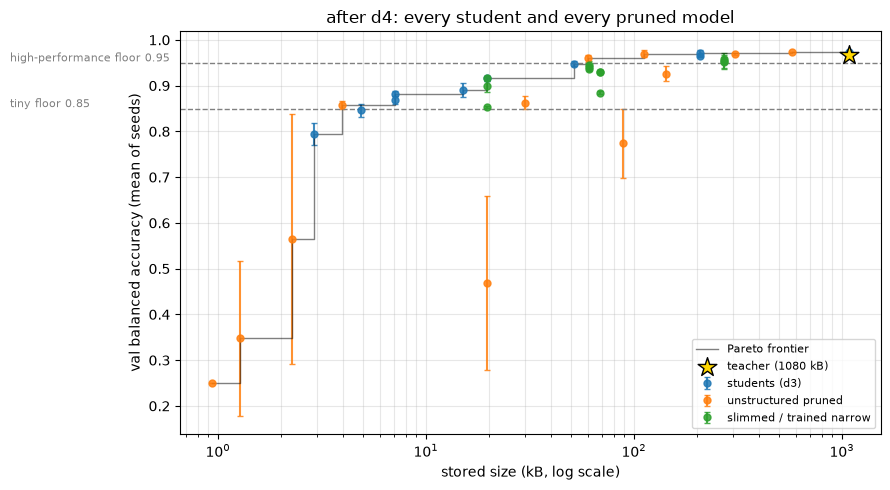

In [5]:
TA = R.table({k: v[0] for k, v in REG.items()})
F = R.pareto(TA)
display(F[["kB", "x smaller than teacher", "params", "sparsity", "bal_acc", "sd"]].round(4))
kind = lambda k: "unstructured pruned" if " pruned " in k else ("slimmed / trained narrow" if ": " in k else "students (d3)")
grp = {g: TA.loc[[k for k in TA.index if kind(k) == g]] for g in ["students (d3)", "unstructured pruned", "slimmed / trained narrow"]}
R.tradeoff_plot(grp, "after d4: every student and every pruned model",
                teacher_acc=json.loads((ARTIFACTS / "compress_rules.json").read_text())["teacher"]["bal_acc"])
plt.tight_layout(); plt.show()
front = [{"label": k, "run": REG[k][1], "bytes": int(F.loc[k, "bytes"]), "bal_acc": float(F.loc[k, "bal_acc"]),
          "sparsity": float(F.loc[k, "sparsity"])} for k in F.index]
_ = (ARTIFACTS / "d4_frontier.json").write_text(json.dumps(front, indent=1))

**Frontier after d4.** Unstructured pruning adds two points that matter:
* **dw-sep 5x5 w32, 75 % pruned: 60 kB, 0.960**, above the 0.95 floor (the dense frontier had nothing between 52 kB
  at 0.948 and 207 kB);
* **dw-sep 5x5 w4, 50 % pruned: 4.0 kB, 0.858**, above the 0.85 floor (the dense frontier's smallest model above it
  was 7.1 kB).

The fine-tuned controls also join the frontier (fine-tuning without pruning is a legitimate way to get a better
model of the same size). The collapsed models (the 7 kB model pruned 75, 90 and 95 %: 0.565, 0.348 and chance) are on the frontier
only because nothing smaller exists; they are kept for completeness. All frontier models go to d5.